# M02-3 | Redo convert_pt2e by Hand: observer → quantize/dequantize

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m02_observer_fakequant/03_observer_to_qdq.ipynb)

M02-2 did `prepare_pt2e` by hand. This notebook does `convert_pt2e` by hand and finally compares the result with it item by item.

First, what `convert_pt2e` does in order (torchao 0.18 `quantize_pt2e.py`):

| Order | Step | What it does | In this notebook |
|---|---|---|---|
| 1 | observer → q/dq | Replace each observer with a quantize/dequantize pair, writing scale and zero point into the graph | Part B |
| 2 | `_fold_conv_bn_qat` | Fold away the conv + bn subgraph left in place during QAT training | Skipped (PTQ already folded BN at prepare, M04) |
| 3 | `DuplicateDQPass` | When one dequantize has multiple users, make a copy for each user | Part C |
| 4 | `PortNodeMetaForQDQ` | Move metadata such as annotations onto the q/dq nodes | Skipped (does not affect graph structure or values) |
| 5 | `constant_fold` | The weight's quantize input is a constant; precompute it and store only int8 | Part D |

Before starting, part **A** first confirms the math of the quantize and dequantize ops.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this course's common/
    os.chdir(f"{repo}/en/m02_observer_fakequant")

In [2]:
import copy

import torch
from torch.fx import Graph
from torch.fx.passes.infra.pass_manager import PassManager
from torch.fx.passes.utils.matcher_utils import SubgraphMatcher

from common.data import calibration_batches
from common.graph_utils import diff_ops, observer_nodes, op_counts
from common.models import example_inputs, get_model
from common.pt2e import DuplicateDQPass, convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)

QD = torch.ops.quantized_decomposed  # the q/dq ops produced by convert_pt2e all live in this namespace

## A. The Math of quantize/dequantize

The two ops are just the M01 formulas: $q = \text{clamp}(\text{round}(x/s) + z,\ q_{\min}, q_{\max})$, $\hat{x} = (q - z)\cdot s$.
Pick a smallish scale so that some elements fall outside the range and get clamped:

In [3]:
x = torch.randn(8) * 2
scale, zp, qmin, qmax = 0.02, 3, -128, 127

q_op = QD.quantize_per_tensor(x, scale, zp, qmin, qmax, torch.int8)
dq_op = QD.dequantize_per_tensor(q_op, scale, zp, qmin, qmax, torch.int8)
q_hand = (torch.round(x / scale) + zp).clamp(qmin, qmax).to(torch.int8)
dq_hand = (q_hand.to(torch.float32) - zp) * scale
clamped = ((torch.round(x / scale) + zp < qmin) | (torch.round(x / scale) + zp > qmax))

table([["x", *[f"{v:.3f}" for v in x.tolist()]],
       ["q (op)", *q_op.tolist()],
       ["q (by hand)", *q_hand.tolist()],
       ["dq (op)", *[f"{v:.3f}" for v in dq_op.tolist()]],
       ["clamped", *["✱" if c else "" for c in clamped.tolist()]]])

x,3.082,-0.587,-4.358,1.137,-2.169,-2.797,0.807,1.676
q (op),127,-26,-128,60,-105,-128,43,87
q (by hand),127,-26,-128,60,-105,-128,43,87
dq (op),2.480,-0.580,-2.620,1.140,-2.160,-2.620,0.800,1.680
clamped,✱,,✱,,,✱,,


In [4]:
assert torch.equal(q_op, q_hand) and torch.equal(dq_op, dq_hand) and clamped.any()

The ops are bit-for-bit identical to the hand-written formulas. Clamped elements come back stopped at the range boundary ($(q_{\max} - z)\cdot s$ or $(q_{\min} - z)\cdot s$); this is the clipping error.

## Setup: a Calibrated, Not-Yet-Converted Graph

`TinyConvNet` (conv-bn-relu, a residual block, linear), prepared with XNNPACKQuantizer (per-channel weights) and calibrated.
`official` is the result of `convert_pt2e`, and every later step is compared against it.

In [5]:
model = get_model("tiny").eval()
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
prepared = prepare_pt2e(export_module(model, example_inputs(8)), quantizer)
with torch.no_grad():
    for batch in calibration_batches(n=128, batch_size=16):
        prepared(*batch)

official = convert_pt2e(copy.deepcopy(prepared))  # convert_pt2e modifies in place, so call it on a copy
x_test = torch.randn(8, 3, 16, 16)


def max_diff(a, b):
    with torch.no_grad():
        return float((a(x_test) - b(x_test)).abs().max())


print(f"Number of observers in the prepared graph = {len(observer_nodes(prepared))}")

Number of observers in the prepared graph = 16


## B. Step 1: observer → q/dq

For each observer: take out the scale and zero point with `calculate_qparams()`, insert quantize and dequantize in front of it, make the downstream consume the dequantize, then delete the observer.
The graph edit is Steps 4 to 5 of M00-4 (replace call_module with call_function, put constants into the graph). Where the scale and zero point go depends on the quantization mode:

- **per-tensor**: scale and zero point are Python numbers, written directly in the node's arguments.
- **per-channel**: scale and zero point are tensors; register them as buffers first, then read them out with `get_attr` nodes.

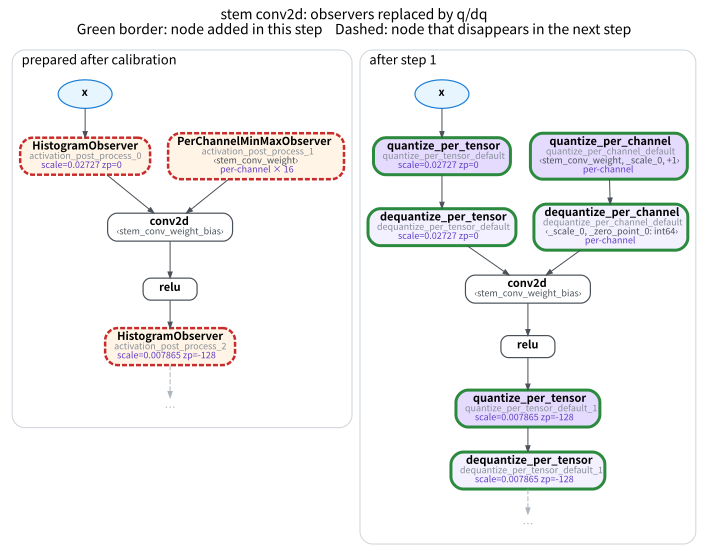

In [6]:
def replace_observers_with_qdq(gm):
    """Replace each observer (call_module) in the graph with quantize → dequantize call_functions."""
    graph = gm.graph
    for k, (node, obs) in enumerate(observer_nodes(gm)):
        scale, zp = obs.calculate_qparams()
        qmin, qmax, dtype = obs.quant_min, obs.quant_max, obs.dtype
        src = node.args[0]
        with graph.inserting_before(node):
            if scale.numel() > 1:  # per-channel: register tensors as buffers and read them with get_attr
                gm.register_buffer(f"_scale_{k}", scale.detach().clone())
                gm.register_buffer(f"_zero_point_{k}", zp.detach().clone())
                s_node, z_node = graph.get_attr(f"_scale_{k}"), graph.get_attr(f"_zero_point_{k}")
                axis = int(obs.ch_axis)
                q = graph.call_function(QD.quantize_per_channel.default, (src, s_node, z_node, axis, qmin, qmax, dtype))
                dq = graph.call_function(QD.dequantize_per_channel.default, (q, s_node, z_node, axis, qmin, qmax, dtype))
            else:                  # per-tensor: Python numbers go directly in the arguments
                s, z = float(scale), int(zp)
                q = graph.call_function(QD.quantize_per_tensor.default, (src, s, z, qmin, qmax, dtype))
                dq = graph.call_function(QD.dequantize_per_tensor.default, (q, s, z, qmin, qmax, dtype))
        node.replace_all_uses_with(dq)
        graph.erase_node(node)
        gm.delete_submodule(node.target)  # discard the observer module once used
    graph.lint()
    gm.recompile()
    return gm


manual = replace_observers_with_qdq(copy.deepcopy(prepared))
draw_stages([(prepared, "prepared after calibration"), (manual, "after step 1")], focus=["conv2d"], hops=2,
            title="stem conv2d: observers replaced by q/dq")

The three observers on the left (dashed, gone after the next step) each become a q/dq pair on the right (green boxes).
The weight's pair is per-channel, and `_scale_0` in its arguments is the buffer just registered; the activation's pair is per-tensor, with the scale written directly in the arguments.

Compare the output with `convert_pt2e`:

In [7]:
print(f"After step 1, max output difference vs. convert_pt2e = {max_diff(official, manual):.3e}")
assert max_diff(official, manual) == 0

After step 1, max output difference vs. convert_pt2e = 0.000e+00


The numbers are already exactly the same. But the graph's op composition still differs in two places (`official` = `convert_pt2e`, `manual` = step 1 only):

In [8]:
table(diff_ops(official, manual, "official", "manual", tablefmt="html"))

op,official,manual,delta
dequantize_per_tensor,12,11,-1
quantize_per_channel,0,5,5
adaptive_avg_pool2d,1,1,0
add,1,1,0
conv2d,4,4,0
dequantize_per_channel,5,5,0
flatten,1,1,0
linear,1,1,0
max_pool2d,2,2,0
quantize_per_tensor,11,11,0


In [9]:
co, cm = op_counts(official), op_counts(manual)
assert co["quantize_per_channel"] == 0 and cm["quantize_per_channel"] == 5
assert co["dequantize_per_tensor"] == cm["dequantize_per_tensor"] + 1

1. `quantize_per_channel`: `official` has none, because the weight's quantize was precomputed (step 5, part D).
2. `dequantize_per_tensor`: `official` has one more (step 3, part C).

## C. Step 3: `DuplicateDQPass`

Find the dequantizes currently shared by multiple users:

In [10]:
def shared_dqs(gm):
    return [n.name for n in gm.graph.nodes
            if n.op == "call_function" and n.target == QD.dequantize_per_tensor.default and len(n.users) > 1]


before = copy.deepcopy(manual)
shared = shared_dqs(manual)
manual = PassManager([DuplicateDQPass()])(manual).graph_module
print(f"Before applying, dequantize shared by multiple users: {shared}")
print(f"After applying: {shared_dqs(manual)}")
assert len(shared) == 1 and shared_dqs(manual) == []

Before applying, dequantize shared by multiple users: ['dequantize_per_tensor_default_2']
After applying: []


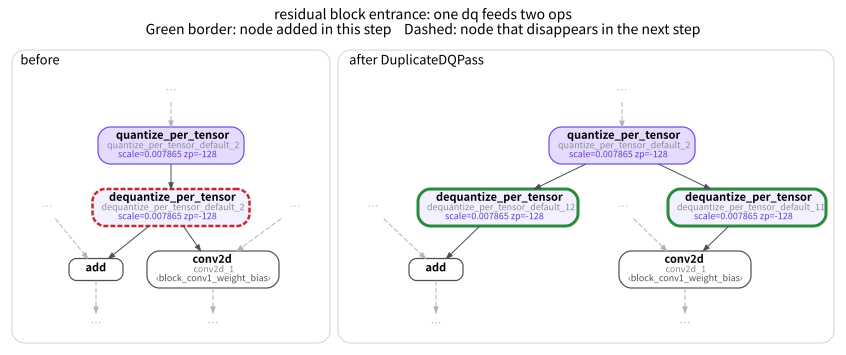

In [11]:
draw_stages([(before, "before"), (manual, "after DuplicateDQPass")], focus=shared,
            title="residual block entrance: one dq feeds two ops")

This is the entrance of the residual block: the same dequantize feeds both `conv2d_1` and `add`. After the pass, each of the two users has its own dequantize.

What is the problem with sharing one dq? As the M01 overview mentioned, for a backend to make int8 actually faster, it looks for the "dq → op → q" pattern in the Q/DQ graph
and replaces the whole segment with one int8 kernel. This act of "replacing the Q/DQ graph with backend kernels" is called **lowering** (done for real from M07 on).

When replacing, the dq inside the pattern disappears with it. But the dq on the left of the figure above must also feed `add`:
if "dq → conv2d_1" is replaced with an int8 conv, `add` loses its input.
So when matching a pattern, if a node inside the pattern still has users outside it, that segment **cannot** count as a successful match.
This is how torch.fx's `SubgraphMatcher` defines it (in the source's `_is_contained`: a matched node may not have users outside the pattern, except for the pattern's inputs and outputs).

Now use `SubgraphMatcher` to look for "dq → conv2d" in both graphs (matching only the first half of the pattern, without comparing argument values) and see which convs match:

In [12]:
def dq_conv_matcher(gm):
    """Pattern for "dequantize → conv2d"; argument count follows the conv2d in the graph, values are not compared (ignore_literals)."""
    conv = next(n for n in gm.graph.nodes if n.target == torch.ops.aten.conv2d.default)
    dq = conv.args[0]
    pattern = Graph()
    xq, w, b = pattern.placeholder("xq"), pattern.placeholder("w"), pattern.placeholder("b")
    x = pattern.call_function(dq.target, (xq, *dq.args[1:]))
    pattern.output(pattern.call_function(conv.target, (x, w, b, *conv.args[3:])))
    return SubgraphMatcher(pattern, ignore_literals=True)


matcher = dq_conv_matcher(manual)


def matched_convs(gm):
    return sorted(n.name for m in matcher.match(gm.graph) for n in m.nodes_map.values()
                  if n.target == torch.ops.aten.conv2d.default)


table([["before (dq shared)", ", ".join(matched_convs(before))],
       ["after DuplicateDQPass", ", ".join(matched_convs(manual))]],
      ["graph", "convs matching \"dq → conv2d\""])

graph,"convs matching ""dq → conv2d"""
before (dq shared),"conv2d, conv2d_2, conv2d_3"
after DuplicateDQPass,"conv2d, conv2d_1, conv2d_2, conv2d_3"


In [13]:
assert "conv2d_1" not in matched_convs(before) and "conv2d_1" in matched_convs(manual)

Before the pass, `conv2d_1` does not match: the dq in front of it must also feed `add`. After the pass, `conv2d_1` and `add` each have their own dq,
"dq → conv2d_1" stands as its own segment, and the backend can replace it with an int8 conv while `add` keeps using its own dq, unaffected.
This is the purpose of `DuplicateDQPass`, and its docstring says the same: users that share one dequantize cannot be annotated and lowered separately.

Copying just adds a node with identical arguments, so the values are exactly equivalent:

In [14]:
print(f"After applying, max output difference vs. convert_pt2e = {max_diff(official, manual):.3e}")
assert max_diff(official, manual) == 0

After applying, max output difference vs. convert_pt2e = 0.000e+00


## D. Step 5: Constant Folding

The weight's quantize input is a constant (a parameter read by `get_attr`), so the result need not wait until run time.
Precompute the int8 weight with the op, register it as a buffer, and have the graph read it with `get_attr`; the original quantize node then has no users.

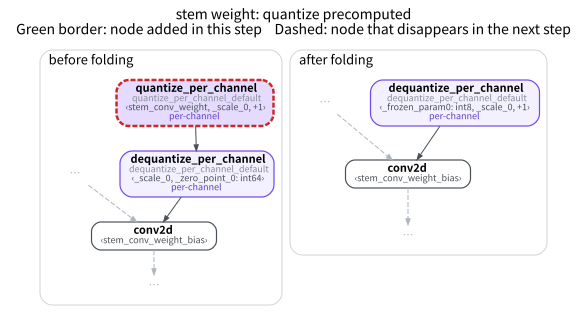

In [15]:
def get_attr_value(gm, target):
    obj = gm
    for part in target.split("."):
        obj = getattr(obj, part)
    return obj


def fold_weight_quantize(gm):
    """The result of quantize_per_channel(get_attr weight) is a constant: precompute it and store as an int8 buffer."""
    graph = gm.graph
    folded = 0
    for node in list(graph.nodes):
        if node.op != "call_function" or node.target != QD.quantize_per_channel.default:
            continue
        if node.args[0].op != "get_attr":  # fold weights only; an activation input is not known until run time
            continue
        w, scale, zp = (get_attr_value(gm, a.target) for a in node.args[:3])
        w_int8 = QD.quantize_per_channel(w, scale, zp, *node.args[3:])  # call the op directly to get the int8 weight
        name = f"_frozen_param{folded}"
        gm.register_buffer(name, w_int8)
        with graph.inserting_before(node):
            new = graph.get_attr(name)
        node.replace_all_uses_with(new)
        graph.erase_node(node)
        folded += 1
    graph.eliminate_dead_code()  # the fp32 weight get_attr has no users now; clean it up too
    graph.lint()
    gm.recompile()
    return folded


before = copy.deepcopy(manual)
n_fold = fold_weight_quantize(manual)
draw_stages([(before, "before folding"), (manual, "after folding")],
            focus=["quantize_per_channel_default", "dequantize_per_channel_default", "conv2d"], hops=0,
            title="stem weight: quantize precomputed")

On the left, `quantize_per_channel` takes the fp32 `stem_conv_weight`; on the right it is gone, and dequantize reads the int8 `_frozen_param0` directly.
The weights the graph actually uses (read by `get_attr`, tensors with ≥ 2 dims; the 1-dim bias does not count) got smaller:

In [16]:
def graph_weight_bytes(gm):
    total = 0
    for n in gm.graph.nodes:
        if n.op == "get_attr":
            t = get_attr_value(gm, n.target)
            if isinstance(t, torch.Tensor) and t.dim() >= 2:
                total += t.numel() * t.element_size()
    return total


table([["before folding", f"{graph_weight_bytes(before):,}"],
       ["after folding", f"{graph_weight_bytes(manual):,}"],
       ["convert_pt2e", f"{graph_weight_bytes(official):,}"]],
      ["graph", "weight size (bytes)"])

graph,weight size (bytes)
before folding,"39,104"
after folding,"9,776"
convert_pt2e,"9,776"


In [17]:
assert n_fold == 5
assert graph_weight_bytes(before) == 4 * graph_weight_bytes(manual) == 4 * graph_weight_bytes(official)

fp32 is 4 bytes and int8 is 1 byte, so the size shrinks by exactly 4x, the same as `convert_pt2e`. One last comparison of op composition and output:

In [18]:
table(diff_ops(official, manual, "official", "manual", tablefmt="html"))

op,official,manual,delta
adaptive_avg_pool2d,1,1,0
add,1,1,0
conv2d,4,4,0
dequantize_per_channel,5,5,0
dequantize_per_tensor,12,12,0
flatten,1,1,0
linear,1,1,0
max_pool2d,2,2,0
quantize_per_tensor,11,11,0
relu,4,4,0


In [19]:
print(f"Max output difference vs. convert_pt2e = {max_diff(official, manual):.3e}")
assert op_counts(official) == op_counts(manual) and max_diff(official, manual) == 0

Max output difference vs. convert_pt2e = 0.000e+00


After the three steps, the hand-written graph is identical to `convert_pt2e` in both op composition and output. The two skipped steps (`_fold_conv_bn_qat`, `PortNodeMetaForQDQ`) do not affect the result on this PTQ graph.

## Summary

- observer → q/dq hard-codes the calibrated scale and zero point into the graph: before convert they live in the observer modules, afterwards they are constants or buffers in the graph.
- convert reads qparams only through `calculate_qparams()` (torchao `convert.py`), and `FakeQuantize` has this method too, so the QAT graph takes the same path.
- The weight's quantize input is a constant, so it can be precomputed and stored as int8 only; the activation's q/dq has to wait for the input at run time and must stay in the graph.
- The result is still a Q/DQ graph: after dequantize it is still an fp32 `conv2d`, so it does not get faster. Switching to integer kernels is the backend's job (M07 to M09).